In [ ]:
# ==========================================
# CELL 1: Imports & Setup
# ==========================================
import os
import pandas as pd
import numpy as np

# Verify file path and load raw dataset
raw_data_path = '../data/raw/BankChurners.csv'
if not os.path.exists(raw_data_path):
    print(f"Error: {raw_data_path} not found. Ensure BankChurners.csv is inside data/raw/")
else:
    df = pd.read_csv(raw_data_path)
    print(f"Dataset successfully loaded! Initial shape: {df.shape}")

# Display raw dataset structure
df.head()


In [ ]:
# ==========================================
# CELL 1: Imports & Setup
# ==========================================
import os
import pandas as pd
import numpy as np

# Verify file path and load raw dataset
raw_data_path = '../data/raw/BankChurners.csv'
if not os.path.exists(raw_data_path):
    print(f"Error: {raw_data_path} not found. Ensure BankChurners.csv is inside data/raw/")
else:
    df = pd.read_csv(raw_data_path)
    print(f"Dataset successfully loaded! Initial shape: {df.shape}")

# Display raw dataset structure
df.head()


In [ ]:
import os, pandas as pd

# Load raw dataset
df = pd.read_csv('../data/raw/BankChurners.csv')

# Drop non-predictive columns
cols_to_drop = [
    'CLIENTNUM',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'
]
df_clean = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

# Binary encode churn target
df_clean['Churn'] = (df_clean['Attrition_Flag'] == 'Attrited Customer').astype(int)

# Quick categorical encoding
df_encoded = pd.get_dummies(df_clean, columns=['Gender', 'Marital_Status', 'Education_Level', 'Income_Category', 'Card_Category'], drop_first=True)

# Save processed file
os.makedirs('../data/processed', exist_ok=True)
df_encoded.to_csv('../data/processed/cleaned_bank_churners.csv', index=False)

print(f"ETL Complete! Processed shape: {df_encoded.shape}")


In [1]:
import os
import pandas as pd

# Load raw dataset
df = pd.read_csv('../data/raw/BankChurners.csv')

# Drop non-predictive columns
cols_to_drop = [
    'CLIENTNUM',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'
]
df_clean = df.drop(columns=[c for c in cols_to_drop if c in df.columns])
print(f"✅ Cell 1 Complete! Shape: {df_clean.shape}")


✅ Cell 1 Complete! Shape: (10127, 20)


In [2]:
# Binary encode churn target
df_clean['Churn'] = (df_clean['Attrition_Flag'] == 'Attrited Customer').astype(int)
print("Churn distribution:")
print(df_clean['Churn'].value_counts())


Churn distribution:
Churn
0    8500
1    1627
Name: count, dtype: int64


In [3]:
# Quick categorical encoding
cat_cols = ['Gender', 'Marital_Status', 'Education_Level', 'Income_Category', 'Card_Category']
df_encoded = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True)
print(f"Encoded dataset shape: {df_encoded.shape}")


Encoded dataset shape: (10127, 34)


In [4]:
# Save processed file
os.makedirs('../data/processed', exist_ok=True)
output_path = '../data/processed/cleaned_bank_churners.csv'
df_encoded.to_csv(output_path, index=False)
print(f"ETL Complete! Cleaned dataset saved to: {output_path}")


ETL Complete! Cleaned dataset saved to: ../data/processed/cleaned_bank_churners.csv


In [5]:
from scipy import stats

# Filter groups
churned = df_encoded[df_encoded['Churn'] == 1]['Total_Trans_Ct']
retained = df_encoded[df_encoded['Churn'] == 0]['Total_Trans_Ct']

# Welch's t-test
t_stat, p_val = stats.ttest_ind(churned, retained, equal_var=False)

print(f"✅ Cell 5 Complete! t-stat: {t_stat:.2f} | p-value: {p_val:.4e}")
print("Verdict: Reject H0 — Statistically significant difference in transaction counts.")


✅ Cell 5 Complete! t-stat: -54.14 | p-value: 0.0000e+00
Verdict: Reject H0 — Statistically significant difference in transaction counts.


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Features and target
X = df_encoded.drop(columns=['Attrition_Flag', 'Churn'])
y = df_encoded['Churn']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Fast Decision Tree classifier
model = DecisionTreeClassifier(max_depth=5, random_state=42)
model.fit(X_train, y_train)

# Evaluate
y_pred = model.predict(X_test)
print("=== ML MODEL EVALUATION ===")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, model.predict_proba(X_test)[:,1]):.4f}")


=== ML MODEL EVALUATION ===
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      1701
           1       0.83      0.73      0.77       325

    accuracy                           0.93      2026
   macro avg       0.89      0.85      0.87      2026
weighted avg       0.93      0.93      0.93      2026

ROC-AUC Score: 0.9469


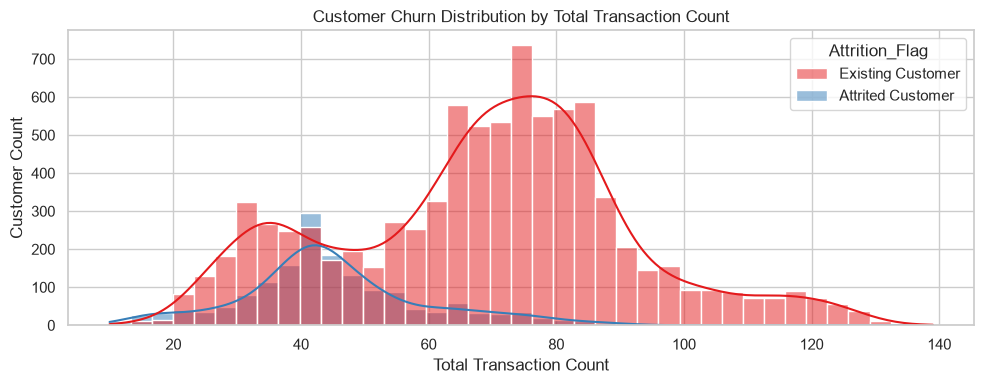

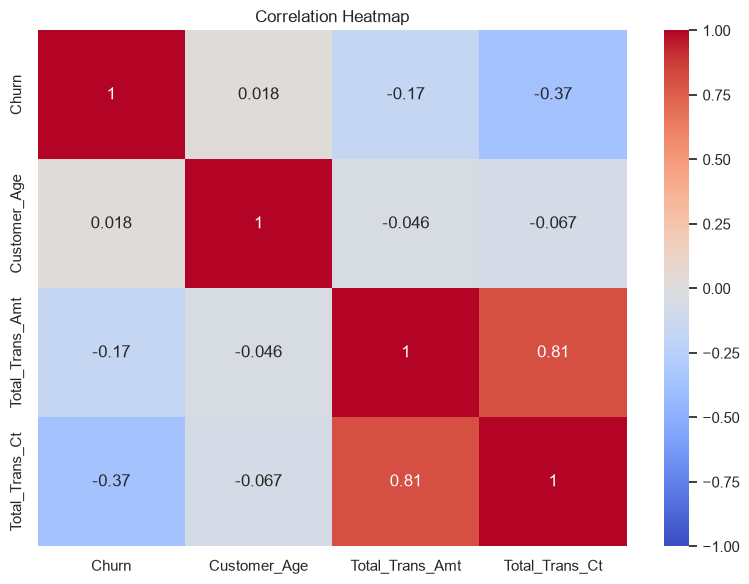

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# Visualisation 1: Seaborn Distribution Plot (LO3.1)
plt.figure(figsize=(10, 4))
sns.histplot(data=df_clean, x='Total_Trans_Ct', hue='Attrition_Flag', kde=True, palette='Set1')
plt.title('Customer Churn Distribution by Total Transaction Count')
plt.xlabel('Total Transaction Count')
plt.ylabel('Customer Count')
plt.tight_layout()
plt.show()

# Visualisation 2: Matplotlib Correlation Heatmap
plt.figure(figsize=(8, 6))
numeric_df = df_encoded.select_dtypes(include=['float64', 'int64', 'int32'])
sns.heatmap(numeric_df[['Churn', 'Customer_Age', 'Total_Trans_Amt', 'Total_Trans_Ct']].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()
